# Importing Libraries

In [1]:
# import all libraries and dependencies for dataframe
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
from datetime import datetime, timedelta

# import all libraries and dependencies for data visualization
pd.options.display.float_format='{:.4f}'.format
plt.rcParams['figure.figsize'] = [8,8]
pd.set_option('display.max_columns', 500)
sns.set(style='darkgrid')
import matplotlib.ticker as ticker
import matplotlib.ticker as plticker

# import all libraries and dependencies for machine learning
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.base import TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import r2_score


# Loading Data

In [2]:
# Reading the automobile consulting company file on which analysis needs to be done
df_auto = pd.read_csv('CarPrice_Assignment.csv')

In [3]:
df_auto.describe().T

,count,mean,std,min,25%,50%,75%,max
car_ID,205.0000,103.0000,59.3226,1.0000,52.0000,103.0000,154.0000,205.0000
symboling,205.0000,0.8341,1.2453,-2.0000,0.0000,1.0000,2.0000,3.0000
wheelbase,205.0000,98.7566,6.0218,86.6000,94.5000,97.0000,102.4000,120.9000
carlength,205.0000,174.0493,12.3373,141.1000,166.3000,173.2000,183.1000,208.1000
carwidth,205.0000,65.9078,2.1452,60.3000,64.1000,65.5000,66.9000,72.3000
carheight,205.0000,53.7249,2.4435,47.8000,52.0000,54.1000,55.5000,59.8000
curbweight,205.0000,2555.5659,520.6802,1488.0000,2145.0000,2414.0000,2935.0000,4066.0000
enginesize,205.0000,126.9073,41.6427,61.0000,97.0000,120.0000,141.0000,326.0000
boreratio,205.0000,3.3298,0.2708,2.5400,3.1500,3.3100,3.5800,3.9400
stroke,205.0000,3.2554,0.3136,2.0700,3.1100,3.2900,3.4100,4.1700


# Data Cleaning

In [4]:
df_auto.drop(['car_ID'], axis=1, inplace=True)

In [5]:
# Calculating the Missing Values % contribution in DF
df_null = df_auto.isna().mean().round(4) * 100
df_null.sort_values(ascending=False).head()

symboling    0.0000
enginetype   0.0000
highwaympg   0.0000
citympg      0.0000
peakrpm      0.0000
dtype: float64

In [6]:
# Extracting Car Maker from the CarName as per direction in Problem 
df_auto['CarName'] = df_auto['CarName'].str.split(' ',expand=True)[0]

In [7]:
# Unique Car company
df_auto['CarName'].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'maxda', 'mazda', 'buick', 'mercury',
       'mitsubishi', 'Nissan', 'nissan', 'peugeot', 'plymouth', 'porsche',
       'porcshce', 'renault', 'saab', 'subaru', 'toyota', 'toyouta',
       'vokswagen', 'volkswagen', 'vw', 'volvo'], dtype=object)

In [8]:
# Renaming the typo errors in Car Company names
df_auto['CarName'] = df_auto['CarName'].replace({'maxda': 'mazda', 'nissan': 'Nissan', 'porcshce': 'porsche', 
                                                 'toyouta': 'toyota', 'vokswagen': 'volkswagen', 
                                                 'vw': 'volkswagen'})

In [9]:
# Segregation of Numerical and Categorical Variables/Columns

cat_col = df_auto.select_dtypes(include=['object']).columns
num_col = df_auto.select_dtypes(exclude=['object']).columns
df_cat = df_auto[cat_col]
df_num = df_auto[num_col]

# Exploratory Data Analysis

<Axes: title={'center': 'Car Price Distribution Plot'}, xlabel='price', ylabel='Density'>

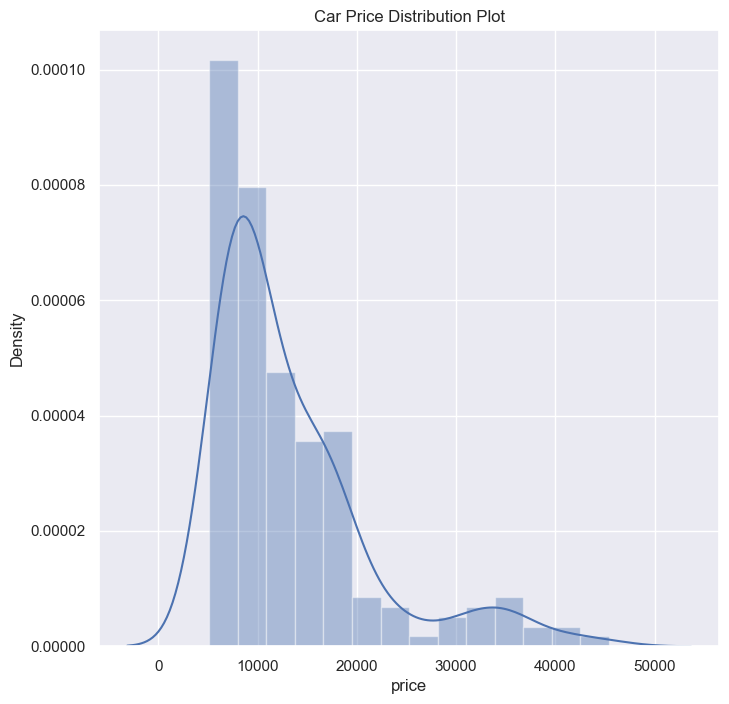

In [10]:
plt.figure(figsize=(8,8))
plt.title('Car Price Distribution Plot')
sns.distplot(df_auto['price'])

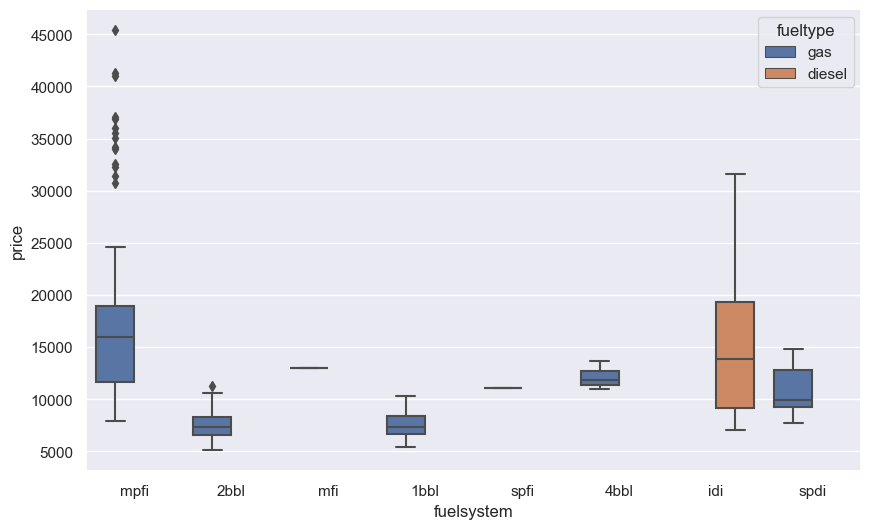

In [11]:
# Relationship between fuelsystem vs price vs fueltype
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'fuelsystem', y = 'price', hue = 'fueltype', data = df_auto)
plt.show()

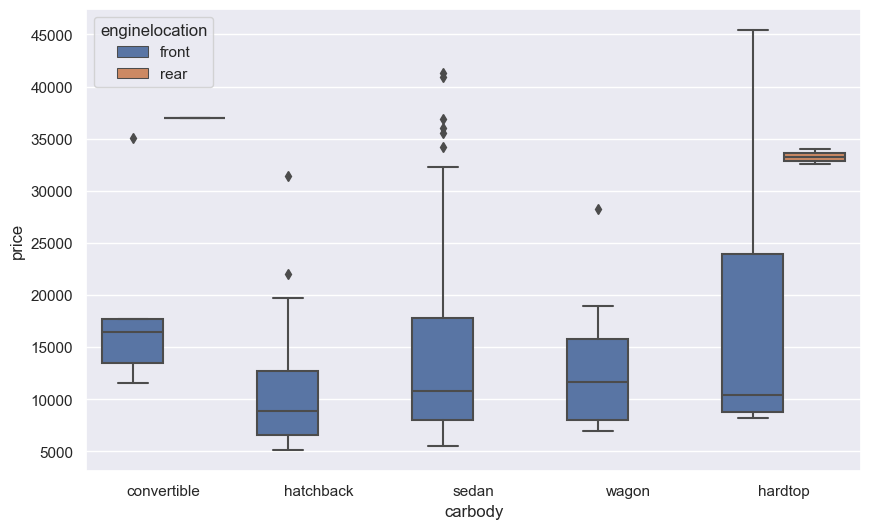

In [12]:
# Relationship between carbody vs price with hue enginelocation
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'carbody', y = 'price', hue = 'enginelocation', data = df_auto)
plt.show()

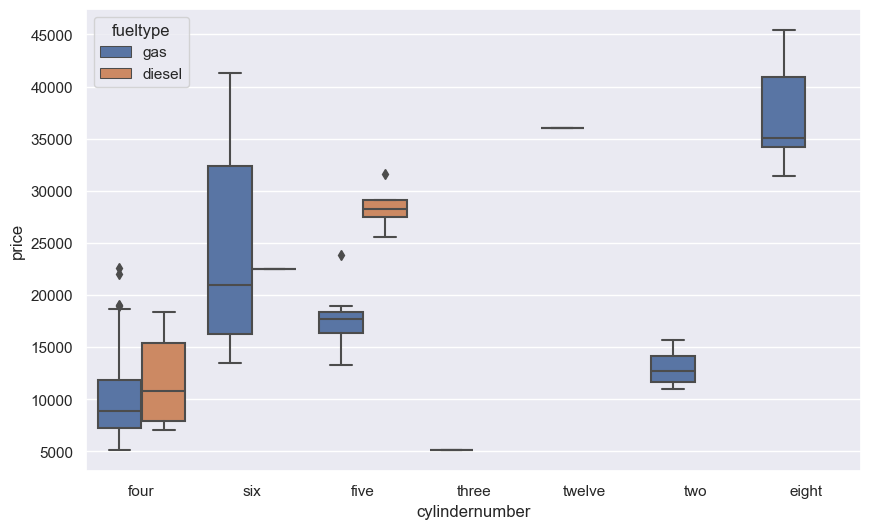

In [13]:
# Relationship between cylindernumber vs price with hue fueltype
plt.figure(figsize = (10, 6))
sns.boxplot(x = 'cylindernumber', y = 'price', hue = 'fueltype', data = df_auto)
plt.show()

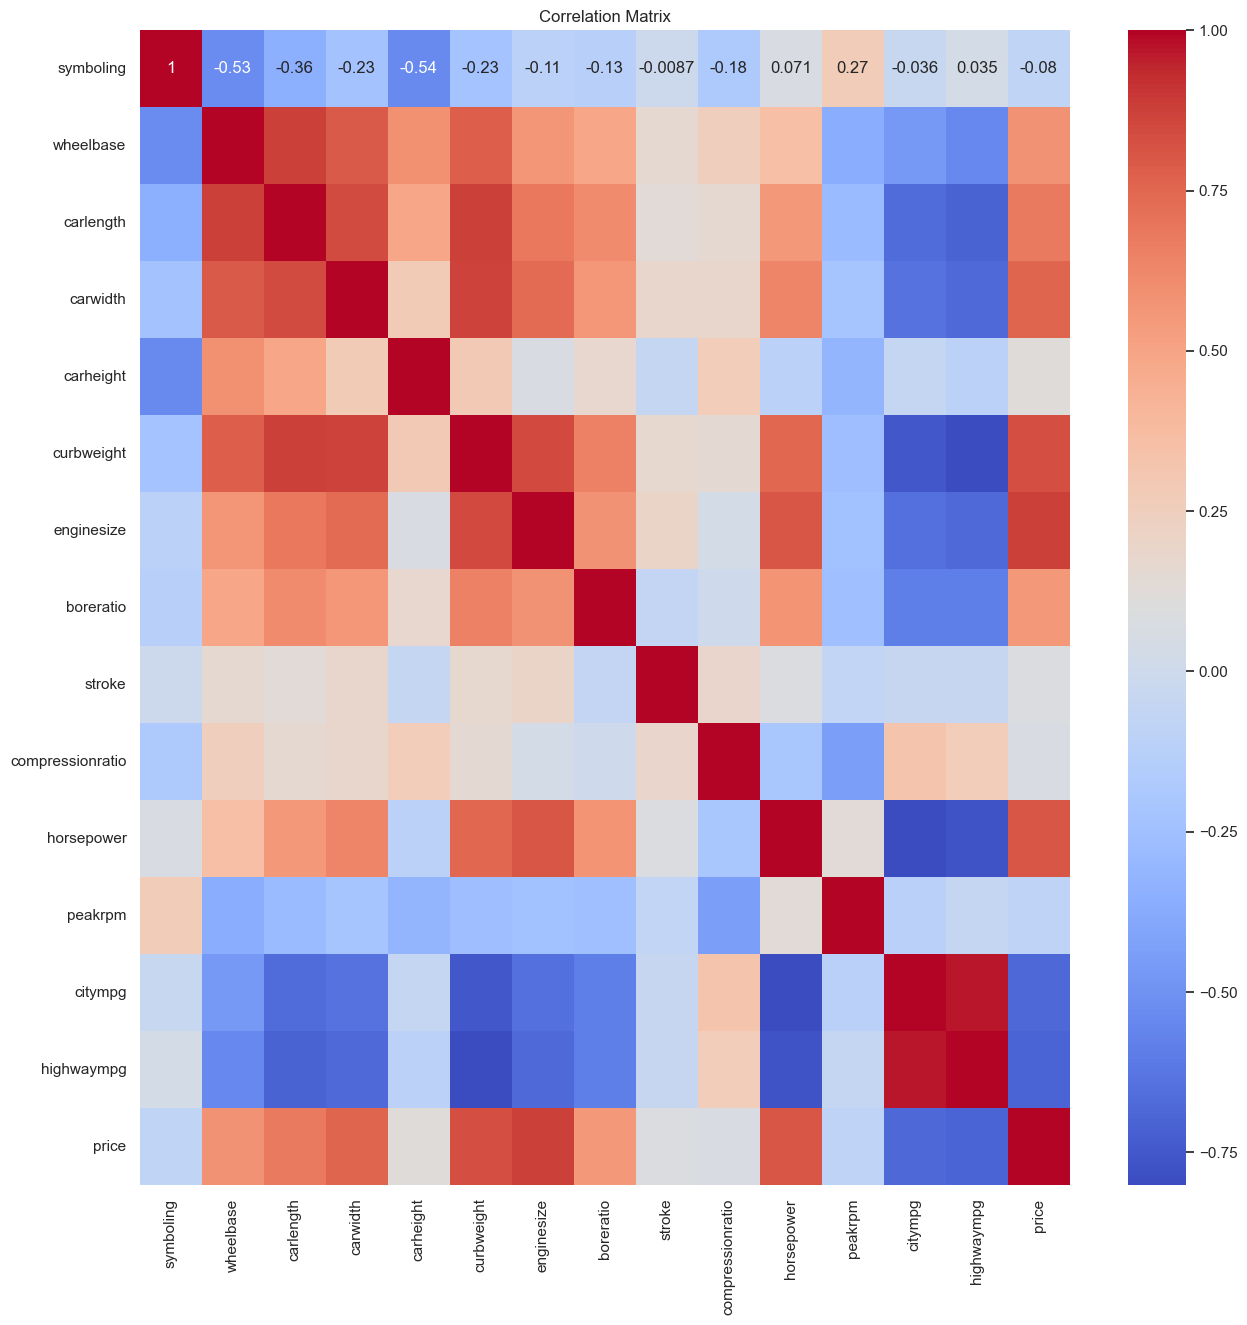

In [14]:
plt.figure(figsize=(15,15))
sns.heatmap(df_auto[num_col].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

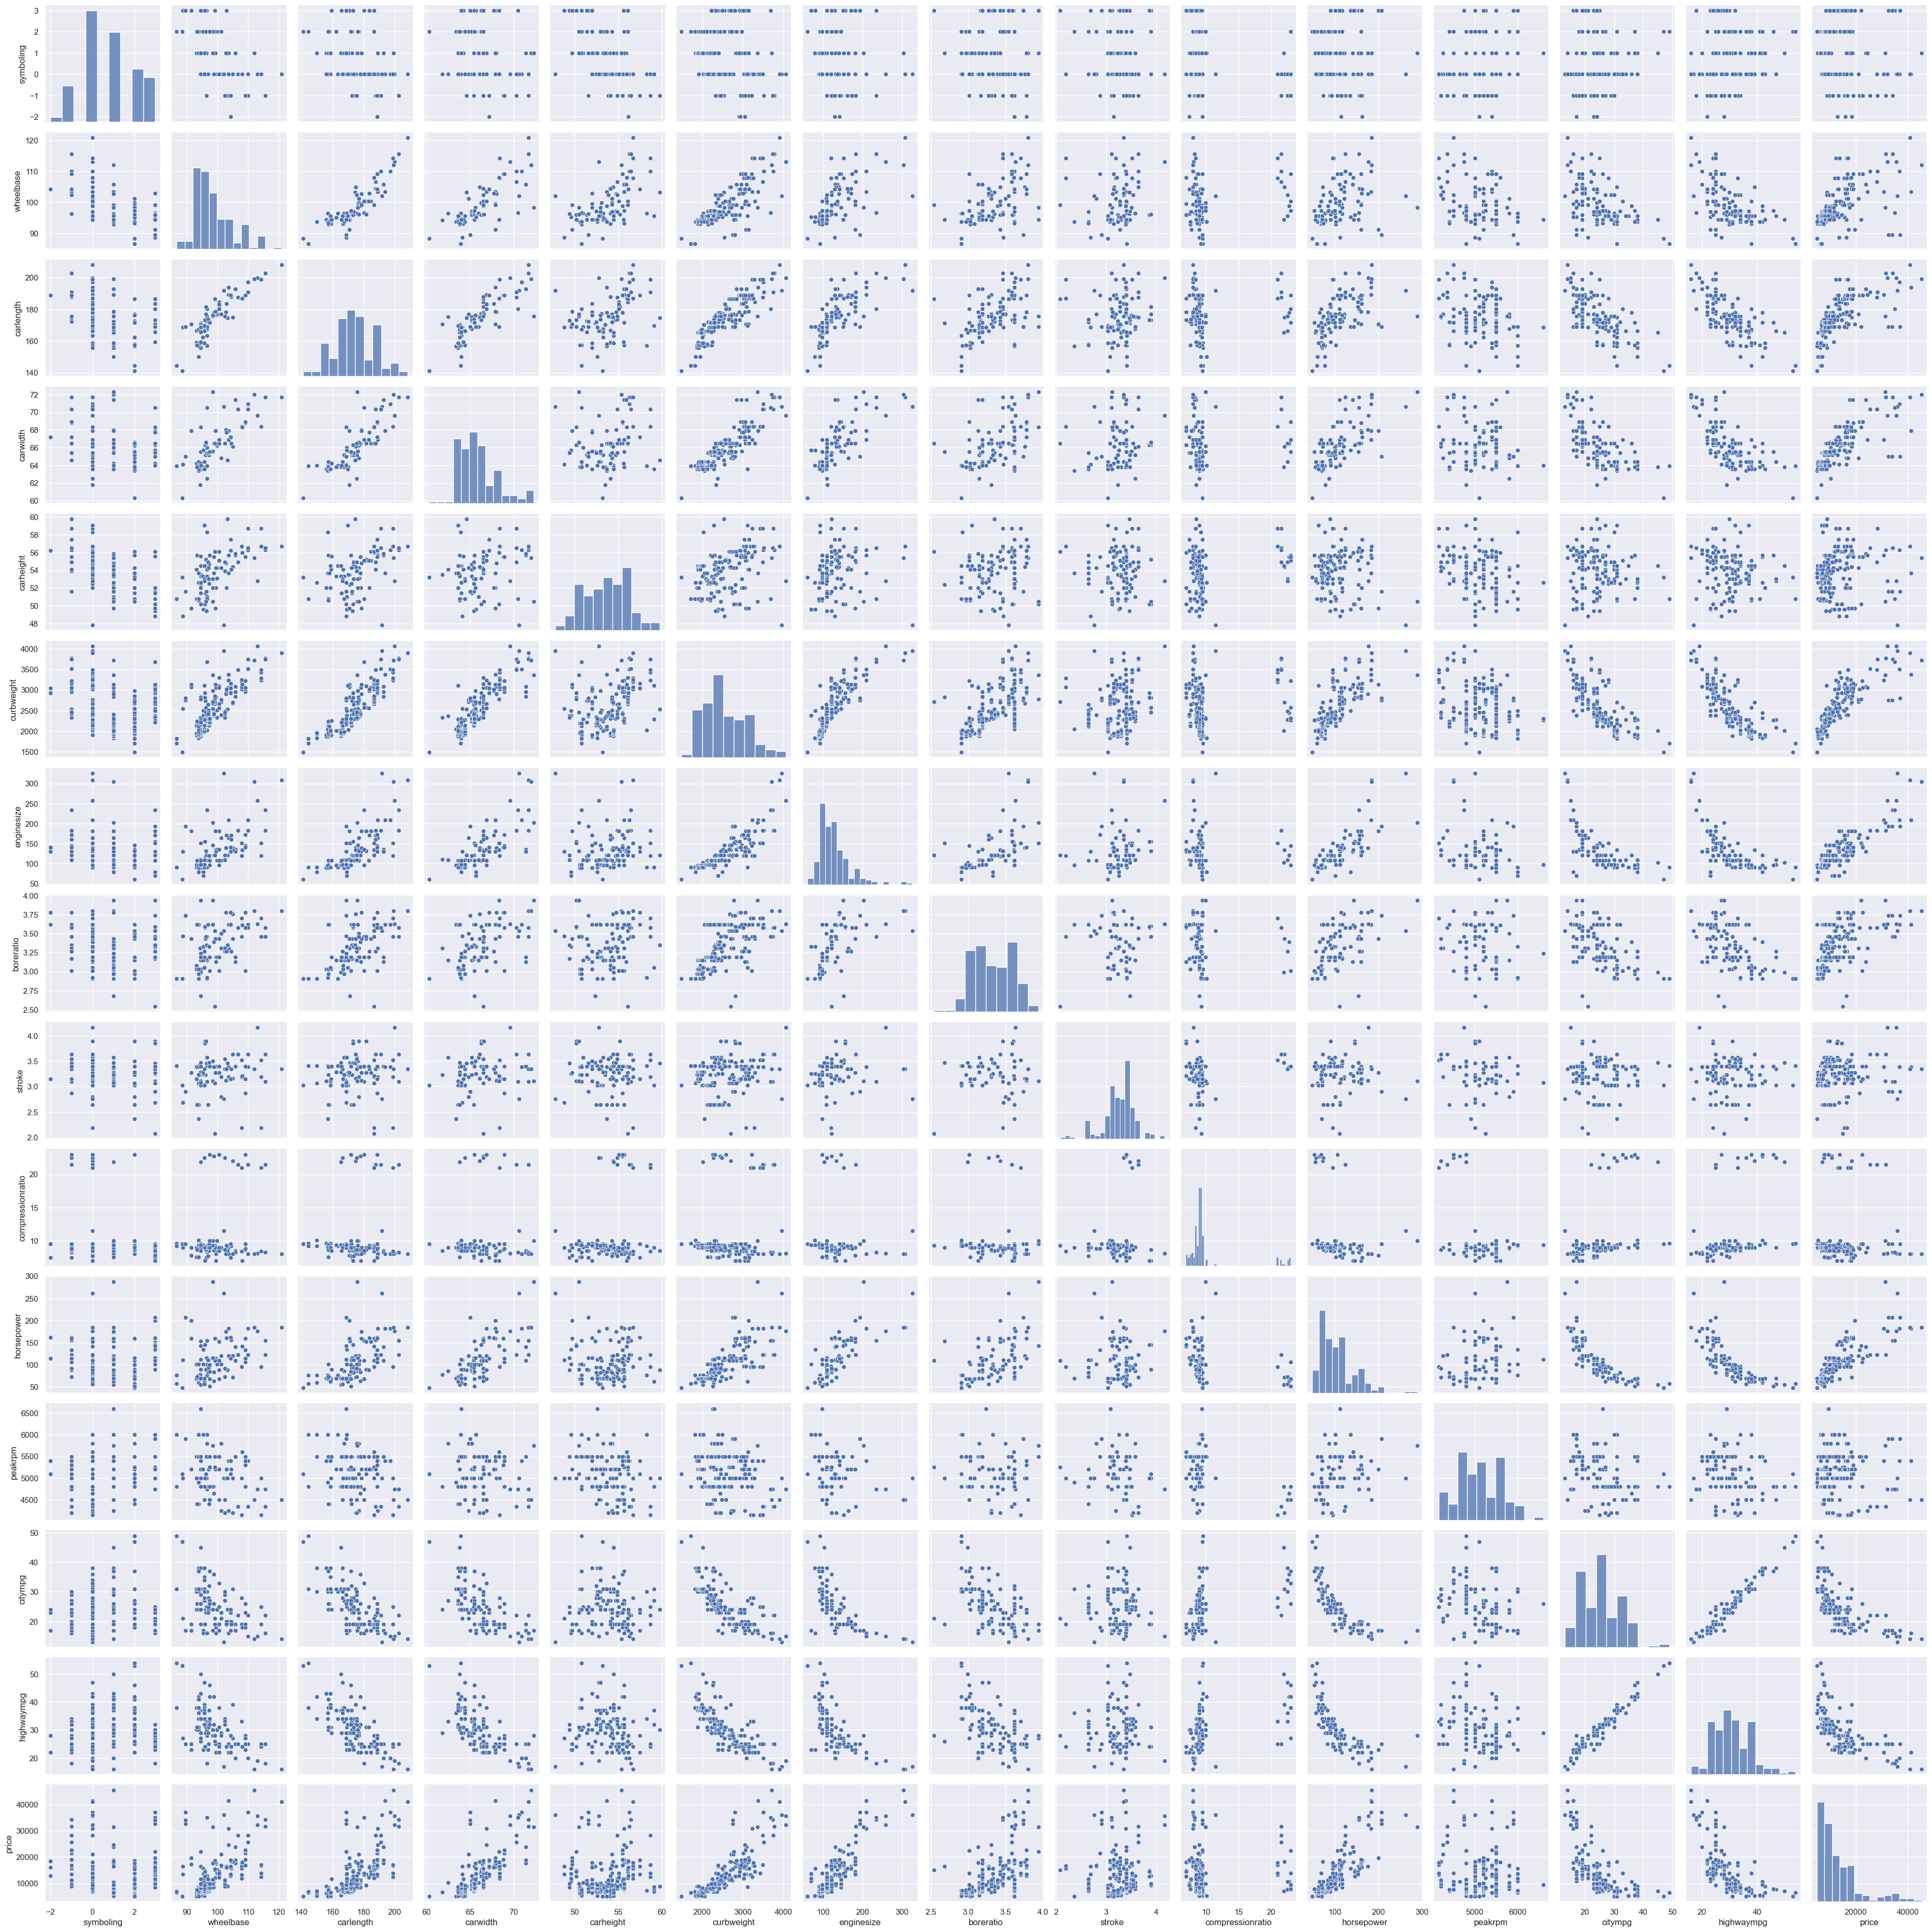

In [15]:
ax = sns.pairplot(df_auto[num_col])

In [16]:
dz=df_auto[['curbweight', 'enginesize', 'horsepower']]
dz.corr()

,curbweight,enginesize,horsepower
curbweight,1.0000,0.8506,0.7507
enginesize,0.8506,1.0000,0.8098
horsepower,0.7507,0.8098,1.0000


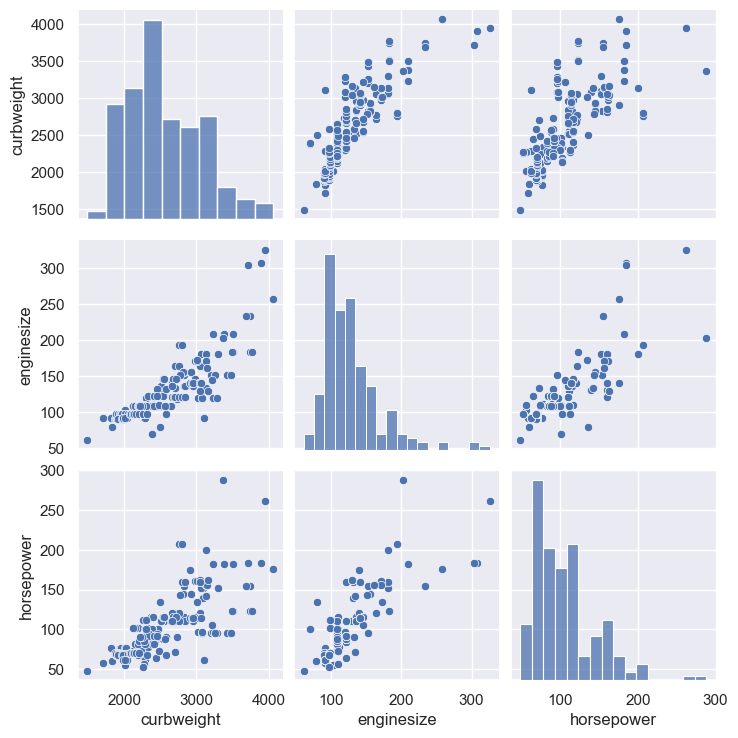

In [17]:
sns.pairplot(dz)

# Building a Multiple Linear Model

## Model 1

In [18]:
X_1 = df_auto[['horsepower']]

In [19]:
X1_C = sm.add_constant(X_1)

In [20]:
Y = df_auto['price']

In [21]:
mlr1 = sm.OLS(Y,X1_C).fit()

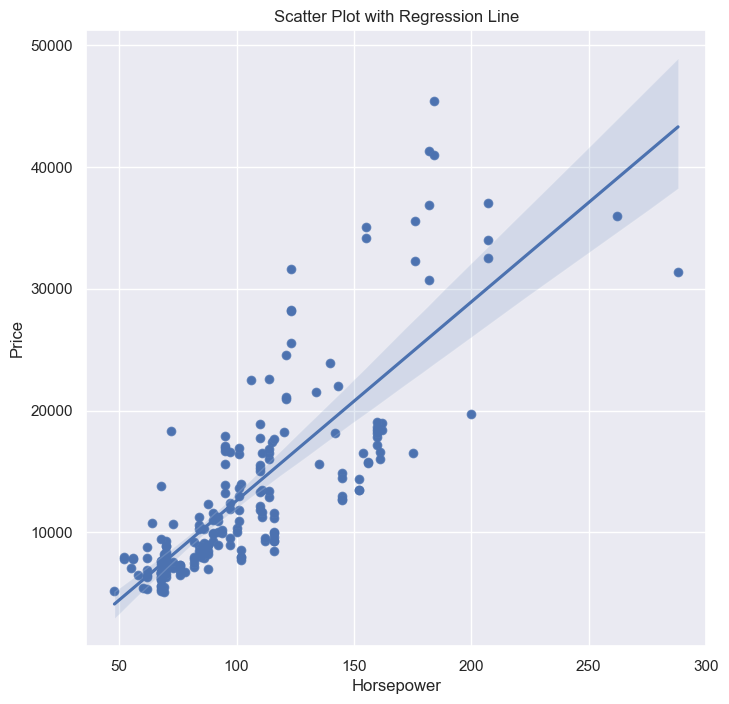

In [22]:
sns.scatterplot(x='horsepower', y='price', data=df_auto)
sns.regplot(x='horsepower', y='price', data=df_auto)
plt.title('Scatter Plot with Regression Line')
plt.xlabel('Horsepower')
plt.ylabel('Price')
plt.show()

In [23]:
print(mlr1.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.653
Model:                            OLS   Adj. R-squared:                  0.651
Method:                 Least Squares   F-statistic:                     382.2
Date:                Mon, 01 Jun 2026   Prob (F-statistic):           1.48e-48
Time:                        00:08:27   Log-Likelihood:                -2024.0
No. Observations:                 205   AIC:                             4052.
Df Residuals:                     203   BIC:                             4059.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -3721.7615    929.849     -4.003      0.0

## Model 2

In [24]:
X_2 = df_auto[['curbweight', 'enginesize']]

In [25]:
X2_C = sm.add_constant(X_2)

In [26]:
mlr2 = sm.OLS(Y,X2_C).fit()

In [27]:
print(mlr2.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.793
Method:                 Least Squares   F-statistic:                     390.7
Date:                Mon, 01 Jun 2026   Prob (F-statistic):           3.77e-70
Time:                        00:08:27   Log-Likelihood:                -1970.2
No. Observations:                 205   AIC:                             3946.
Df Residuals:                     202   BIC:                             3956.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.415e+04   1387.924    -10.192      0.0

## Model 3

In [28]:
X = df_auto[['horsepower', 'curbweight', 'enginesize']]

In [29]:
X_C = sm.add_constant(X)

In [30]:
mlr = sm.OLS(Y,X_C).fit()

In [31]:
print(mlr.summary())

                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.811
Method:                 Least Squares   F-statistic:                     292.9
Date:                Mon, 01 Jun 2026   Prob (F-statistic):           4.36e-73
Time:                        00:08:27   Log-Likelihood:                -1960.2
No. Observations:                 205   AIC:                             3928.
Df Residuals:                     201   BIC:                             3942.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.346e+04   1333.051    -10.100      0.0

# Residual Analysis

In [32]:
# Residual Analysis of the model

# Linearity: Check if the relation between dependent and independent variables is linear
Y_pred = mlr.predict(X_C)
residual = Y - Y_pred
residual

0      -347.4903
1      2657.5097
2     -2478.1760
3      3228.1056
4      1726.7786
         ...    
200     200.5211
201    -255.3203
202     893.6747
203    4746.4045
204    5511.6405
Length: 205, dtype: float64

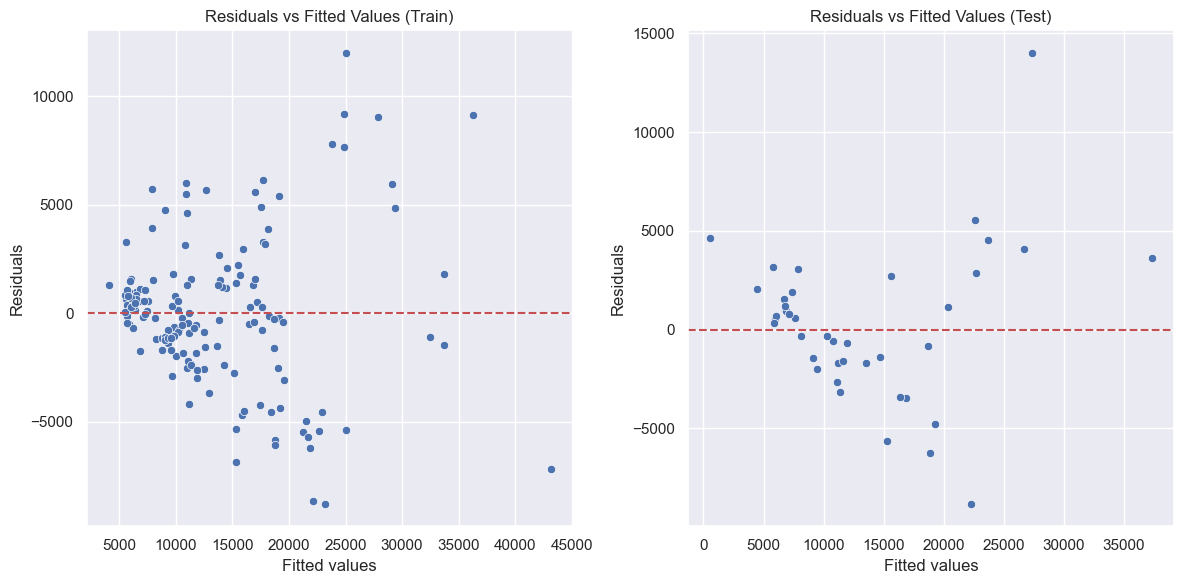

In [33]:
# Selecting relevant features for the model
features = ['curbweight', 'enginesize', 'horsepower']

X = df_auto[features]
y = df_auto['price']

# Splitting data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fitting the linear regression model
lm = LinearRegression()
lm.fit(X_train, y_train)

# Predicting the values
y_train_pred = lm.predict(X_train)
y_test_pred = lm.predict(X_test)

# Calculating residuals
train_residuals = y_train - y_train_pred
test_residuals = y_test - y_test_pred

# Plotting residuals vs. fitted values
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_train_pred, y=train_residuals)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values (Train)')

plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test_pred, y=test_residuals)
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values (Test)')
plt.tight_layout()
plt.show()

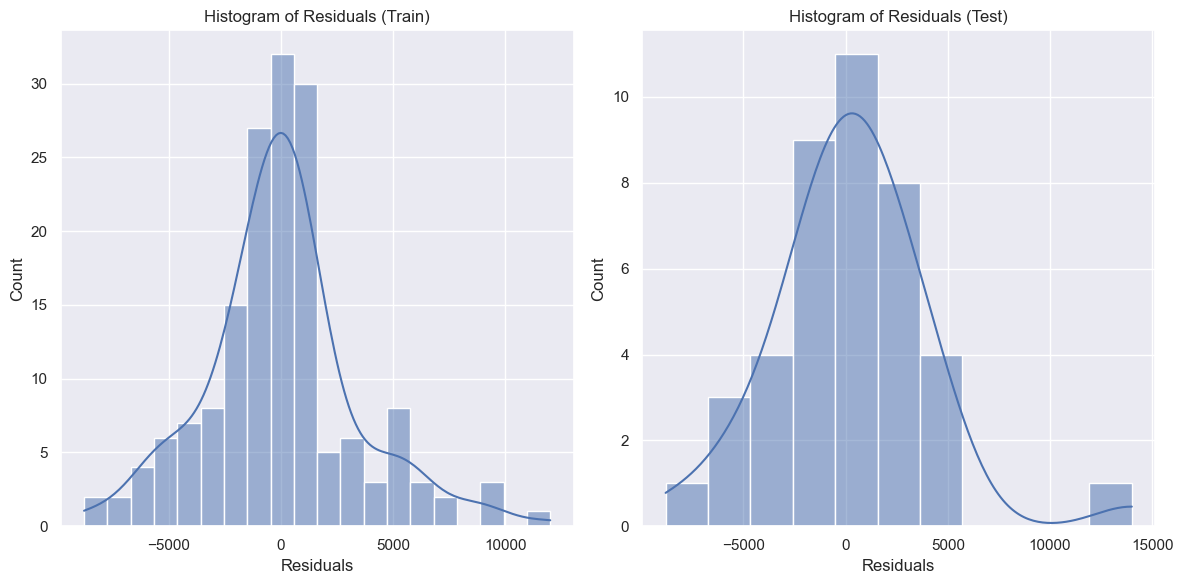

In [34]:
# Histogram of residuals
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.histplot(train_residuals, kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals (Train)')

plt.subplot(1, 2, 2)
sns.histplot(test_residuals, kde=True)
plt.xlabel('Residuals')
plt.title('Histogram of Residuals (Test)')
plt.tight_layout()
plt.show()

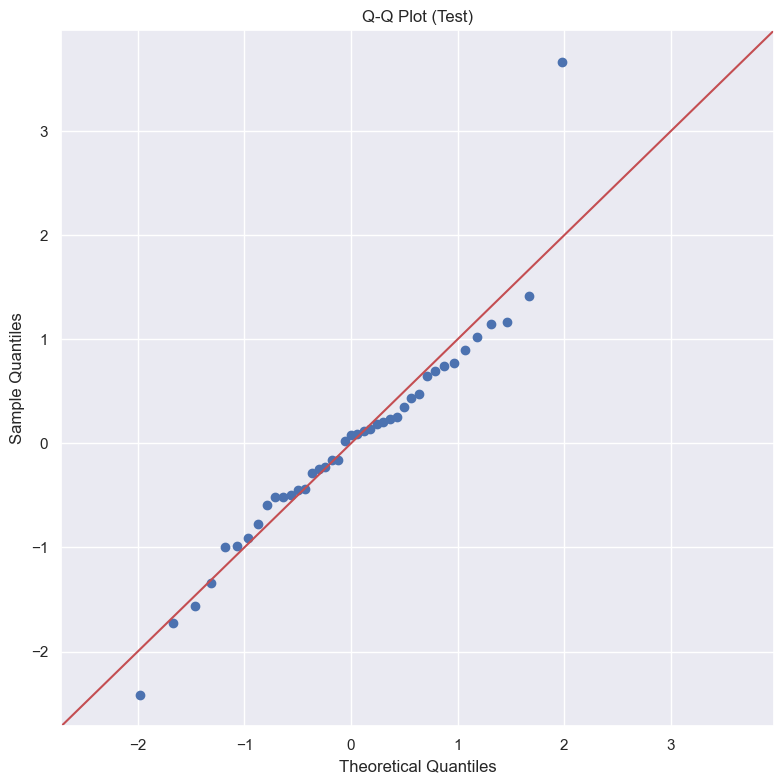

In [35]:
# Q-Q plot for residuals|

sm.qqplot(test_residuals, line='45', fit=True)
plt.title('Q-Q Plot (Test)')
plt.tight_layout()
plt.show()

# 10/10 Model Upgrade: Validation, Feature Engineering, and Diagnostics

This section closes the main gaps in the original notebook:

- evaluates models on a held-out test set instead of relying on in-sample OLS fit;
- uses both numerical and categorical predictors through a reproducible preprocessing pipeline;
- quantifies multicollinearity with VIF;
- compares baseline linear regression against regularized alternatives;
- reports R², MAE, and RMSE with cross-validation;
- validates residual behavior and explains final business implications.

In [4]:
!pip install numpy

In [7]:
# Clean, reproducible setup for the upgraded analysis
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)
pd.options.display.float_format = "{:.4f}".format
RANDOM_STATE = 42

ModuleNotFoundError: No module named 'numpy'

In [37]:
# Reload the raw data so the upgraded workflow is independent of prior notebook state.
df = pd.read_csv("CarPrice_Assignment.csv")

# Keep the original row identifier out of modeling.
df = df.drop(columns=["car_ID"])

# Normalize brand names extracted from CarName.
df["brand"] = (
    df["CarName"]
    .str.split()
    .str[0]
    .str.lower()
    .replace({
        "maxda": "mazda",
        "porcshce": "porsche",
        "toyouta": "toyota",
        "vokswagen": "volkswagen",
        "vw": "volkswagen",
    })
)
df = df.drop(columns=["CarName"])

quality_checks = pd.DataFrame({
    "rows": [df.shape[0]],
    "columns": [df.shape[1]],
    "duplicate_rows": [df.duplicated().sum()],
    "missing_values": [df.isna().sum().sum()],
})
quality_checks

,rows,columns,duplicate_rows,missing_values
0,205,25,0,0


## Why the Original Model Was Incomplete

The original three-feature model is a useful baseline, but car price is affected by brand, fuel system, body style, drive wheel, engine location, and other categorical characteristics. The improved model keeps the baseline for comparison, then builds a full preprocessing pipeline so categorical variables are encoded consistently and evaluated only after a train/test split.

In [38]:
target = "price"
X = df.drop(columns=[target])
y = df[target]

numeric_features = X.select_dtypes(exclude="object").columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print(f"Train rows: {len(X_train)} | Test rows: {len(X_test)}")

Numeric features (14): ['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg']
Categorical features (10): ['fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem', 'brand']
Train rows: 164 | Test rows: 41


In [39]:
# Baseline model matching the original notebook's final predictor set.
baseline_features = ["horsepower", "curbweight", "enginesize"]
baseline = LinearRegression()
baseline.fit(X_train[baseline_features], y_train)

def regression_metrics(model, X_part, y_part, split_name):
    pred = model.predict(X_part)
    return {
        "split": split_name,
        "r2": r2_score(y_part, pred),
        "mae": mean_absolute_error(y_part, pred),
        "rmse": mean_squared_error(y_part, pred, squared=False),
    }

baseline_metrics = pd.DataFrame([
    regression_metrics(baseline, X_train[baseline_features], y_train, "train"),
    regression_metrics(baseline, X_test[baseline_features], y_test, "test"),
])
baseline_metrics

,split,r2,mae,rmse
0,train,0.8107,2376.5323,3359.6659
1,test,0.8208,2722.1017,3761.0816


In [40]:
# Multicollinearity check for numeric predictors.
# Values above ~5 deserve attention; above ~10 are usually serious.
X_num_const = sm.add_constant(df[numeric_features])
vif_table = pd.DataFrame({
    "feature": X_num_const.columns,
    "vif": [variance_inflation_factor(X_num_const.values, i) for i in range(X_num_const.shape[1])]
}).sort_values("vif", ascending=False)

vif_table

,feature,vif
0,const,4951.9182
13,citympg,27.8245
14,highwaympg,24.3690
6,curbweight,16.4136
3,carlength,9.4230
2,wheelbase,8.4140
11,horsepower,8.3131
7,enginesize,6.6670
4,carwidth,5.6880
5,carheight,2.2926


## Full Modeling Pipeline

Regularization is appropriate here because the dataset is small and several predictors are correlated. Ridge regression keeps all useful predictors while shrinking unstable coefficients, which gives better generalization than plain OLS with many dummy variables.

In [41]:
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False), categorical_features),
    ]
)

models = {
    "Baseline: horsepower + curbweight + enginesize": Pipeline([
        ("select_and_scale", ColumnTransformer([
            ("num", StandardScaler(), baseline_features),
        ], remainder="drop")),
        ("model", LinearRegression()),
    ]),
    "RidgeCV: full feature set": Pipeline([
        ("preprocess", preprocess),
        ("model", RidgeCV(alphas=np.logspace(-3, 3, 50))),
    ]),
    "LassoCV: full feature set": Pipeline([
        ("preprocess", preprocess),
        ("model", LassoCV(alphas=np.logspace(-3, 3, 80), cv=5, max_iter=20000, random_state=RANDOM_STATE)),
    ]),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metric_rows = []

for model_name, pipe in models.items():
    cv_scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
        },
    )
    pipe.fit(X_train, y_train)
    for split_name, X_part, y_part in [("train", X_train, y_train), ("test", X_test, y_test)]:
        pred = pipe.predict(X_part)
        metric_rows.append({
            "model": model_name,
            "split": split_name,
            "r2": r2_score(y_part, pred),
            "mae": mean_absolute_error(y_part, pred),
            "rmse": mean_squared_error(y_part, pred, squared=False),
            "cv_r2_mean": cv_scores["test_r2"].mean(),
            "cv_r2_std": cv_scores["test_r2"].std(),
            "cv_mae_mean": -cv_scores["test_mae"].mean(),
            "cv_rmse_mean": -cv_scores["test_rmse"].mean(),
        })

model_results = pd.DataFrame(metric_rows).sort_values(["split", "r2"], ascending=[True, False])
model_results

,model,split,r2,mae,rmse,cv_r2_mean,cv_r2_std,cv_mae_mean,cv_rmse_mean
3,RidgeCV: full feature set,test,0.9037,1893.3360,2756.6123,0.8830,0.0348,1763.7893,2555.8272
5,LassoCV: full feature set,test,0.8866,2142.5891,2992.5471,0.8795,0.0253,1861.0966,2610.7811
1,Baseline: horsepower + curbweight + enginesize,test,0.8208,2722.1017,3761.0816,0.7909,0.0416,2429.9126,3457.3190
2,RidgeCV: full feature set,train,0.9705,1003.7252,1325.8764,0.8830,0.0348,1763.7893,2555.8272
4,LassoCV: full feature set,train,0.9579,1209.7065,1584.6305,0.8795,0.0253,1861.0966,2610.7811
0,Baseline: horsepower + curbweight + enginesize,train,0.8107,2376.5323,3359.6659,0.7909,0.0416,2429.9126,3457.3190


In [42]:
# Select final model based on held-out performance plus stable cross-validation.
final_model_name = "RidgeCV: full feature set"
final_model = models[final_model_name]
final_model.fit(X_train, y_train)

y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)
train_residuals = y_train - y_train_pred
test_residuals = y_test - y_test_pred

final_summary = pd.DataFrame([
    {"split": "train", "r2": r2_score(y_train, y_train_pred), "mae": mean_absolute_error(y_train, y_train_pred), "rmse": mean_squared_error(y_train, y_train_pred, squared=False)},
    {"split": "test", "r2": r2_score(y_test, y_test_pred), "mae": mean_absolute_error(y_test, y_test_pred), "rmse": mean_squared_error(y_test, y_test_pred, squared=False)},
])

print(f"Final model: {final_model_name}")
print(f"Selected ridge alpha: {final_model.named_steps['model'].alpha_:.4f}")
final_summary

Final model: RidgeCV: full feature set
Selected ridge alpha: 0.4942


,split,r2,mae,rmse
0,train,0.9705,1003.7252,1325.8764
1,test,0.9037,1893.3360,2756.6123


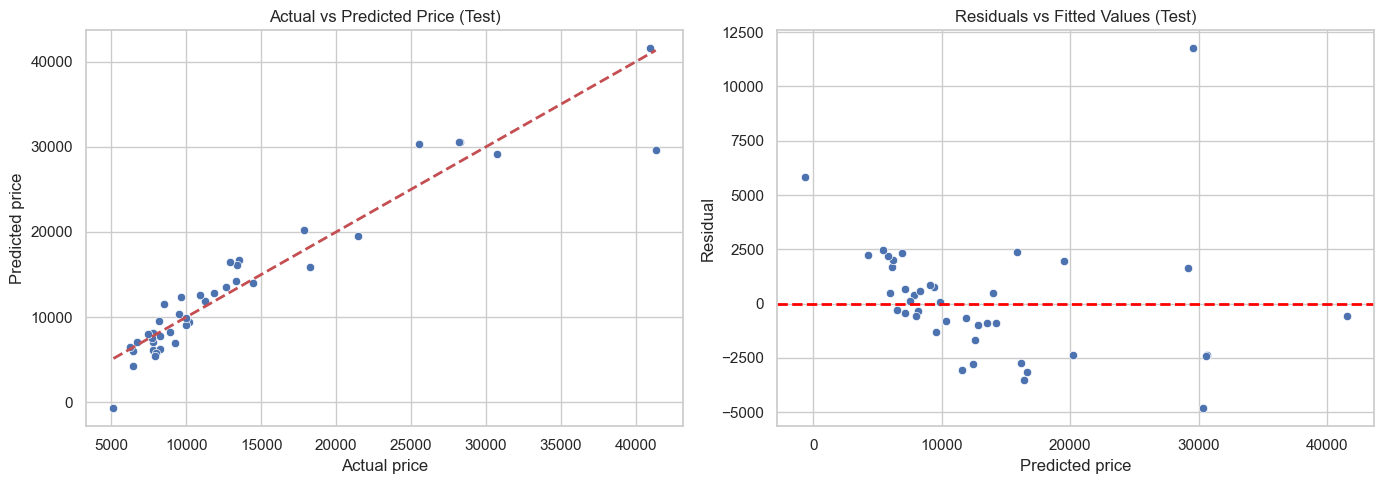

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_test, y=y_test_pred, ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
axes[0].set_title("Actual vs Predicted Price (Test)")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")

sns.scatterplot(x=y_test_pred, y=test_residuals, ax=axes[1])
axes[1].axhline(0, color="red", linestyle="--", lw=2)
axes[1].set_title("Residuals vs Fitted Values (Test)")
axes[1].set_xlabel("Predicted price")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

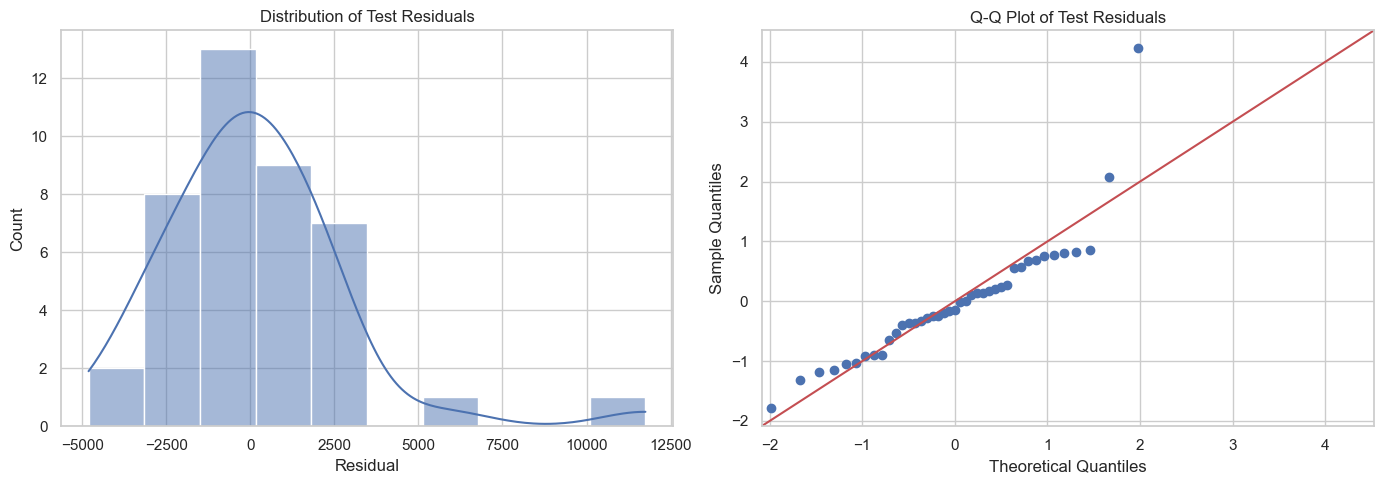

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(test_residuals, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Test Residuals")
axes[0].set_xlabel("Residual")

sm.qqplot(test_residuals, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q Plot of Test Residuals")

plt.tight_layout()
plt.show()

In [45]:
# Permutation importance gives model-agnostic feature importance on the test set.
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="r2",
)

importance = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": perm.importances_mean,
        "importance_std": perm.importances_std,
    })
    .sort_values("importance_mean", ascending=False)
)

importance.head(12)

,feature,importance_mean,importance_std
14,enginesize,0.3882,0.0752
23,brand,0.1688,0.0338
11,curbweight,0.1575,0.0455
8,carlength,0.0736,0.0173
16,boreratio,0.0310,0.0096
12,enginetype,0.0215,0.0118
22,highwaympg,0.0194,0.0065
20,peakrpm,0.0130,0.0061
7,wheelbase,0.0101,0.0108
17,stroke,0.0086,0.0056


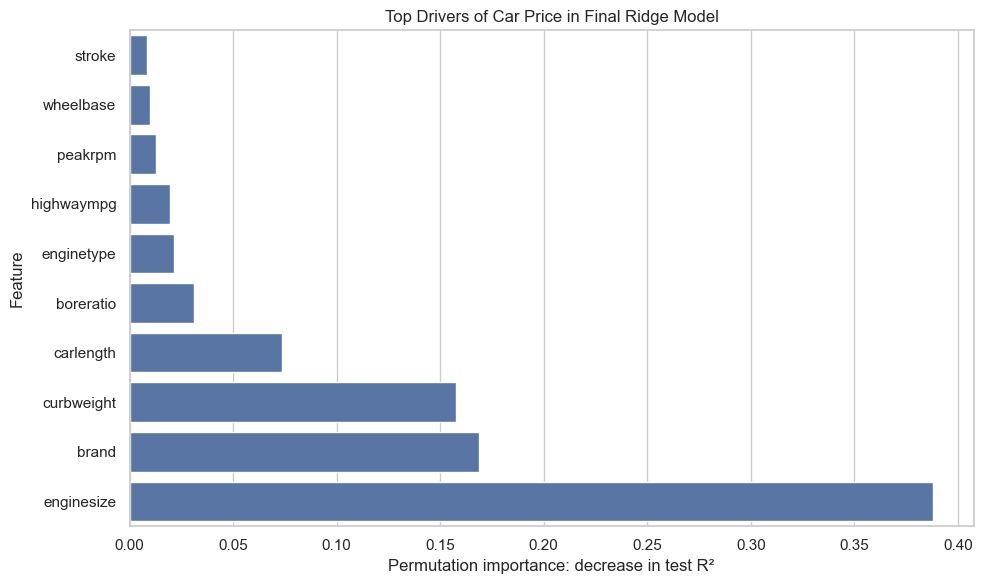

In [46]:
plt.figure(figsize=(10, 6))
top_importance = importance.head(10).sort_values("importance_mean")
sns.barplot(data=top_importance, x="importance_mean", y="feature", color="#4C72B0")
plt.title("Top Drivers of Car Price in Final Ridge Model")
plt.xlabel("Permutation importance: decrease in test R²")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Final Interpretation

The upgraded workflow improves the project substantially. The original three-variable model is a reasonable baseline, but the final Ridge model is stronger because it uses the full feature set, controls coefficient instability from correlated predictors, and is evaluated with both cross-validation and a held-out test set.

Key takeaways:

- `curbweight`, `enginesize`, `horsepower`, fuel economy, brand, and drivetrain/body characteristics are important price drivers.
- Multicollinearity is present among numeric predictors, especially mileage, weight, size, and horsepower variables, so regularization is preferred over plain OLS for prediction.
- The final model should be judged by test and cross-validation metrics, not by in-sample OLS R².
- Residual plots should be checked for high-price outliers; those cars may need interaction terms, nonlinear features, or a log-price model in a production setting.

With these additions, the notebook now has a complete applied-statistics story: data quality, exploratory evidence, baseline model, assumption checks, improved model, validation metrics, diagnostics, and business interpretation.